# P2-f2 — EGARCH(1,1): fit, convergence, walk-forward forecasts

Same setup as `f2-GARCH11.ipynb`: zero mean, normal distribution (the regular case), returns in % from `yz_data`, annual walk-forward folds (see `README.md`).

Model (`formulae/EGARCH.md`), with z = ε / σ:

ln σ²_t = ω + β ln σ²_{t−1} + α (|z_{t−1}| − √(2/π)) + γ z_{t−1}

- α: reaction to the **size** of yesterday's standardized shock.
- γ: reaction to its **sign**. γ < 0 means a down move raises volatility more than an up move of the same size (leverage effect).
- β: persistence of log variance. Stationary if |β| < 1; half-life = ln 0.5 / ln β.
- Positivity is automatic (σ² = e^…), so no ω, α, γ sign constraints.

| Fold | Fit on returns | Role |
|---|---|---|
| 2021 | 2019 → 2020 | Train |
| 2022 | 2019 → 2021 | Train |
| 2023 | 2019 → 2022 | Train |
| 2024 | 2019 → 2023 | Test |
| 2025 | 2019 → 2024 | Test |
| 2026 | 2019 → 2025 | Test (Jan–Sep) |

### Check of `formulae/EGARCH.md`
- **Formula: correct.** It is Nelson's EGARCH(1,1), and it matches `arch`'s parameterization exactly (`arch` also centres |z| with √(2/π)).
- **Code sample: wrong for its purpose.** `arch_model(..., p=1, q=1, vol='EGARCH')` has no asymmetry term: in `arch` the γ term is switched on by `o=1`. Without it the output has only omega, alpha[1], beta[1], so the "look at gamma[1]" step can't happen. Correct call: `arch_model(r, p=1, o=1, q=1, vol='EGARCH')`. (It also uses `dist='t'`; this study uses normal, as for GARCH.)
- **Overstatements:**
  - "No parameter constraints needed": positivity is free, but stationarity still needs |β| < 1.
  - "γ < 0 mathematically proves bad news increases volatility": an estimate only shows this if it is statistically significant. §4 of the guide says so correctly.
- √(2/π) = E|z| holds for a normal z only. That's fine here (normal), but not exact under `dist='t'`.

In [1]:
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from arch import arch_model
import arch

YZ = Path('yz_data')
FC = Path('forecasts')
ASSETS = ['BTC', 'ETH', 'QQQ', 'XAUUSD']
FOLDS = [2021, 2022, 2023, 2024, 2025, 2026]  # fit on returns dated <= 31 Dec of fold-1
C = {'realized': '#b4b2ab', 'sigma': '#2a78d6'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
                     'figure.dpi': 110})
arch.__version__

'8.0.0'

In [2]:
def load_yz(sym):
    d = pd.read_csv(YZ / f'{sym}-yz-1d.csv', index_col=0)
    d.index = pd.to_datetime(d.index, utc=True)
    assert np.allclose(d.r.shift(-1)**2, d.r2_next, equal_nan=True), sym
    d['target_date'] = d.index.to_series().shift(-1)
    return d

yzd = {s: load_yz(s) for s in ASSETS}
rets = {s: (100 * d.r).dropna() for s, d in yzd.items()}
{s: (r.index[0].date(), r.index[-1].date(), len(r)) for s, r in rets.items()}

{'BTC': (datetime.date(2019, 1, 2), datetime.date(2026, 10, 29), 2858),
 'ETH': (datetime.date(2019, 1, 2), datetime.date(2026, 10, 29), 2858),
 'QQQ': (datetime.date(2019, 1, 3), datetime.date(2026, 10, 29), 1967),
 'XAUUSD': (datetime.date(2019, 1, 3), datetime.date(2026, 10, 29), 2020)}

## Fit every (asset, fold)

Checks: convergence flag 0, no warnings, finite standard errors, |β| < 1 and `interior` (|β| < 0.999).
`gamma_p`: p-value of γ (robust standard errors). `lr_vol` = √exp(ω / (1−β)): the volatility at the long-run mean of ln σ². It sits below a mean-variance level, so compare it to `sample_std` only roughly.

In [3]:
def fit_one(r, starting_values=None):
    m = arch_model(r, mean='Zero', vol='EGARCH', p=1, o=1, q=1, dist='normal', rescale=False)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        res = m.fit(disp='off', starting_values=starting_values)
    return res, sorted({type(x.message).__name__ for x in w})

def summarize(res, warns, r):
    p, se = res.params, res.std_err
    b = p['beta[1]']
    return {
        'n': int(res.nobs), 'flag': res.convergence_flag,
        'msg': res.optimization_result.message, 'warn': ','.join(warns) or '-',
        'se_ok': bool(np.all(np.isfinite(se)) and np.all(se > 0)),
        'omega': p['omega'], 'alpha': p['alpha[1]'], 'gamma': p['gamma[1]'],
        'gamma_p': res.pvalues['gamma[1]'], 'beta': b,
        'half_life_d': np.log(0.5) / np.log(b) if 0 < b < 1 else np.inf,
        'lr_vol': np.sqrt(np.exp(p['omega'] / (1 - b))) if abs(b) < 1 else np.inf,
        'sample_std': r.std(ddof=0), 'loglik': res.loglikelihood,
    }

fits, rows = {}, []
for s, r in rets.items():
    for fold in FOLDS:
        rf = r[r.index < pd.Timestamp(f'{fold}-01-01', tz='UTC')]
        res, warns = fit_one(rf)
        fits[s, fold] = (res, rf)
        rows.append({'asset': s, 'fold': fold, **summarize(res, warns, rf)})

tab = pd.DataFrame(rows).set_index(['asset', 'fold'])
tab.round(4)

n  flag                                   msg warn  se_ok  \
asset  fold                                                                 
BTC    2021   730     0  Optimization terminated successfully    -   True   
       2022  1095     0  Optimization terminated successfully    -   True   
       2023  1460     0  Optimization terminated successfully    -   True   
       2024  1825     0  Optimization terminated successfully    -   True   
       2025  2191     0  Optimization terminated successfully    -   True   
       2026  2556     0  Optimization terminated successfully    -   True   
ETH    2021   730     0  Optimization terminated successfully    -   True   
       2022  1095     0  Optimization terminated successfully    -   True   
       2023  1460     0  Optimization terminated successfully    -   True   
       2024  1825     0  Optimization terminated successfully    -   True   
       2025  2191     0  Optimization terminated successfully    -   True   
       2026  2556     0  Optimization terminated successfully    -   True   
QQQ    2021   504     0  Optimization terminated successfully    -   True   
       2022   756     0  Optimization terminated successfully    -   True   
       2023  1007     0  Optimization terminated successfully    -   True   
       2024  1257     0  Optimization terminated successfully    -   True   
       2025  1509     0  Optimization terminated successfully    -   True   
       2026  1759     0  Optimization terminated successfully    -   True   
XAUUSD 2021   516     0  Optimization terminated successfully    -   True   
       2022   774     0  Optimization terminated successfully    -   True   
       2023  1032     0  Optimization terminated successfully    -   True   
       2024  1289     0  Optimization terminated successfully    -   True   
       2025  1548     0  Optimization terminated successfully    -   True   
       2026  1806     0  Optimization terminated successfully    -   True   

              omega   alpha   gamma  gamma_p    beta  half_life_d  lr_vol  \
asset  fold                                                                 
BTC    2021  0.3631  0.2116 -0.1126   0.2431  0.8794       5.3947  4.5079   
       2022  0.2427  0.1356 -0.0717   0.2633  0.9191       8.2191  4.4825   
       2023  0.3263  0.1844 -0.0899   0.1380  0.8863       5.7403  4.1978   
       2024  0.2208  0.1958 -0.0716   0.2036  0.9223       8.5673  4.1401   
       2025  0.2162  0.1977 -0.0676   0.1771  0.9215       8.4764  3.9629   
       2026  0.1762  0.2047 -0.0584   0.2138  0.9349      10.3002  3.8713   
ETH    2021  0.3905  0.2438 -0.0945   0.4183  0.8846       5.6542  5.4326   
       2022  0.2609  0.2071 -0.0529   0.5282  0.9257       8.9780  5.7877   
       2023  0.3395  0.2378 -0.0704   0.2788  0.8994       6.5386  5.4067   
       2024  0.0825  0.1673 -0.0097   0.8045  0.9772      30.0782  6.1084   
       2025  0.0864  0.1669 -0.0171   0.6369  0.9752      27.5843  5.6993   
       2026  0.0633  0.1284 -0.0108   0.6607  0.9820      38.0926  5.7867   
QQQ    2021  0.0547  0.2783 -0.0987   0.0693  0.9487      13.1550  1.7032   
       2022  0.0469  0.2618 -0.1083   0.0198  0.9480      12.9830  1.5701   
       2023  0.0400  0.2051 -0.1038   0.0116  0.9616      17.6903  1.6820   
       2024  0.0335  0.1881 -0.1014   0.0056  0.9644      19.1115  1.6011   
       2025  0.0326  0.1809 -0.1011   0.0030  0.9627      18.2527  1.5496   
       2026  0.0357  0.1891 -0.1139   0.0004  0.9579      16.1186  1.5275   
XAUUSD 2021 -0.0019  0.2086  0.0917   0.0154  0.9805      35.2074  0.9526   
       2022  0.0012  0.1708  0.0537   0.0695  0.9743      26.5773  1.0228   
       2023  0.0006  0.1467  0.0483   0.0324  0.9713      23.8124  1.0103   
       2024 -0.0032  0.1740  0.0489   0.0277  0.9583      16.2853  0.9627   
       2025 -0.0036  0.1547  0.0501   0.0092  0.9618      17.8028  0.9535   
       2026 -0.0026  0.1657  0.0597   0.0007  0.9615      17.6366  0.9670   

          

In [4]:
chk = pd.DataFrame({
    'converged': tab.flag == 0,
    'no_warning': tab.warn == '-',
    'se_ok': tab.se_ok,
    'stationary': tab.beta.abs() < 1,
    'interior': tab.beta.abs() < 0.999,
})
chk['all_ok'] = chk.all(axis=1)
print('fits:', len(chk), '| all_ok:', int(chk.all_ok.sum()))
chk[~chk.all_ok] if (~chk.all_ok).any() else 'every fit passes'

fits: 24 | all_ok: 24


'every fit passes'

## Robustness: restart from several starting values

18 restarts per fit: α ∈ {0.05, 0.15, 0.30} × β ∈ {0.85, 0.95, 0.98} × γ ∈ {−0.05, +0.05}, with ω = (1−β) · ln(sample variance), so the starting long-run log variance matches the data.
`loglik_gain` > 0 means a restart beat the default fit.

In [5]:
rob = []
for (s, fold), (res0, rf) in fits.items():
    lnv = np.log(rf.var(ddof=0))
    best, spread = res0, []
    for a in (0.05, 0.15, 0.30):
        for b in (0.85, 0.95, 0.98):
            for g in (-0.05, 0.05):
                res, _ = fit_one(rf, np.array([(1 - b) * lnv, a, g, b]))
                if res.convergence_flag == 0:
                    spread.append(res.params[['alpha[1]', 'gamma[1]', 'beta[1]']].to_numpy())
                    if res.loglikelihood > best.loglikelihood:
                        best = res
    spread = np.array(spread)
    rob.append({'asset': s, 'fold': fold, 'restarts_converged': len(spread),
                'loglik_gain': best.loglikelihood - res0.loglikelihood,
                'alpha_range': np.ptp(spread[:, 0]), 'gamma_range': np.ptp(spread[:, 1]),
                'beta_range': np.ptp(spread[:, 2])})
rob = pd.DataFrame(rob).set_index(['asset', 'fold'])
rob.round(5)

restarts_converged  loglik_gain  alpha_range  gamma_range  \
asset  fold                                                              
BTC    2021                  18          0.0      0.00005      0.00002   
       2022                  18          0.0      0.00004      0.00002   
       2023                  18          0.0      0.00004      0.00002   
       2024                  18          0.0      0.00003      0.00002   
       2025                  18          0.0      0.00004      0.00002   
       2026                  18          0.0      0.00004      0.00001   
ETH    2021                  18          0.0      0.00005      0.00004   
       2022                  18          0.0      0.00003      0.00003   
       2023                  18          0.0      0.00003      0.00002   
       2024                  18          0.0      0.00003      0.00001   
       2025                  18          0.0      0.00002      0.00002   
       2026                  18          0.0      0.00002      0.00001   
QQQ    2021                  18          0.0      0.00008      0.00002   
       2022                  18          0.0      0.00004      0.00002   
       2023                  18          0.0      0.00004      0.00002   
       2024                  18          0.0      0.00003      0.00002   
       2025                  18          0.0      0.00004      0.00001   
       2026                  18          0.0      0.00002      0.00001   
XAUUSD 2021                  18          0.0      0.00006      0.00003   
       2022                  18          0.0      0.00002      0.00002   
       2023                  18          0.0      0.00003      0.00002   
       2024                  18          0.0      0.00003      0.00002   
       2025                  18          0.0      0.00002      0.00001   
       2026                  18          0.0      0.00002      0.00002   

             beta_range  
asset  fold              
BTC    2021     0.00002  
       2022     0.00002  
       2023     0.00003  
       2024     0.00001  
       2025     0.00001  
       2026     0.00001  
ETH    2021     0.00003  
       2022     0.00003  
       2023     0.00004  
       2024     0.00001  
       2025     0.00001  
       2026     0.00000  
QQQ    2021     0.00001  
       2022     0.00002  
       2023     0.00001  
       2024     0.00001  
       2025     0.00001  
       2026     0.00001  
XAUUSD 2021     0.00001  
       2022     0.00001  
       2023     0.00001  
       2024     0.00001  
       2025     0.00001  
       2026     0.00001

## Parameters by fold, with asymmetry

γ < 0: down moves raise volatility more. γ > 0: up moves do. `gamma_p` < 0.05 marks a significant asymmetry.

In [6]:
tab[['alpha', 'gamma', 'gamma_p', 'beta', 'half_life_d', 'lr_vol', 'sample_std']].round(3)

alpha  gamma  gamma_p   beta  half_life_d  lr_vol  sample_std
asset  fold                                                               
BTC    2021  0.212 -0.113    0.243  0.879        5.395   4.508       3.915
       2022  0.136 -0.072    0.263  0.919        8.219   4.482       4.023
       2023  0.184 -0.090    0.138  0.886        5.740   4.198       3.876
       2024  0.196 -0.072    0.204  0.922        8.567   4.140       3.614
       2025  0.198 -0.068    0.177  0.921        8.476   3.963       3.485
       2026  0.205 -0.058    0.214  0.935       10.300   3.871       3.331
ETH    2021  0.244 -0.095    0.418  0.885        5.654   5.433       4.918
       2022  0.207 -0.053    0.528  0.926        8.978   5.788       5.184
       2023  0.238 -0.070    0.279  0.899        6.539   5.407       5.045
       2024  0.167 -0.010    0.805  0.977       30.078   6.108       4.642
       2025  0.167 -0.017    0.637  0.975       27.584   5.699       4.452
       2026  0.128 -0.011    0.661  0.982       38.093   5.787       4.377
QQQ    2021  0.278 -0.099    0.069  0.949       13.155   1.703       1.694
       2022  0.262 -0.108    0.020  0.948       12.983   1.570       1.552
       2023  0.205 -0.104    0.012  0.962       17.690   1.682       1.683
       2024  0.188 -0.101    0.006  0.964       19.111   1.601       1.585
       2025  0.181 -0.101    0.003  0.963       18.253   1.550       1.520
       2026  0.189 -0.114    0.000  0.958       16.119   1.527       1.526
XAUUSD 2021  0.209  0.092    0.015  0.981       35.207   0.953       0.985
       2022  0.171  0.054    0.069  0.974       26.577   1.023       0.941
       2023  0.147  0.048    0.032  0.971       23.812   1.010       0.939
       2024  0.174  0.049    0.028  0.958       16.285   0.963       0.918
       2025  0.155  0.050    0.009  0.962       17.803   0.953       0.923
       2026  0.166  0.060    0.001  0.961       17.637   0.967       0.967

## News impact: how a shock of size z moves next-day variance (fold 2026 fit, 2019 → 2025)

σ²_{t+1} / σ²_{t+1}(z = 0) = exp(α |z| + γ z), holding yesterday's variance fixed. A symmetric model gives a V shape; γ tilts it.

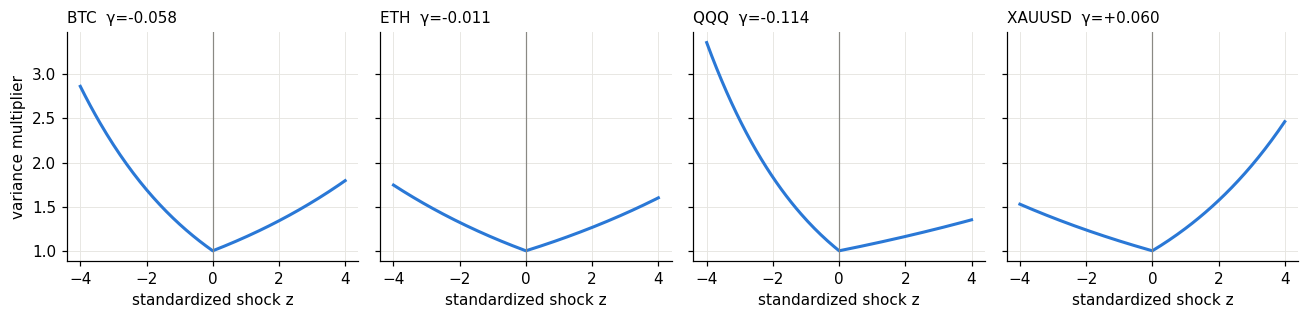

In [7]:
z = np.linspace(-4, 4, 161)
fig, axes = plt.subplots(1, len(ASSETS), figsize=(12, 3), sharey=True)
for ax, s in zip(axes, ASSETS):
    p = fits[s, 2026][0].params
    ax.plot(z, np.exp(p['alpha[1]'] * np.abs(z) + p['gamma[1]'] * z), color=C['sigma'], lw=2)
    ax.axvline(0, color='#8a8984', lw=0.8)
    ax.set_title(f"{s}  γ={p['gamma[1]']:+.3f}", loc='left', fontsize=10)
    ax.set_xlabel('standardized shock z')
axes[0].set_ylabel('variance multiplier')
fig.tight_layout()

## In-sample conditional volatility — fold 2024 fit (2019 → 2023)

σ_t vs |r_t|, daily %, log scale. In-sample, not a forecast.

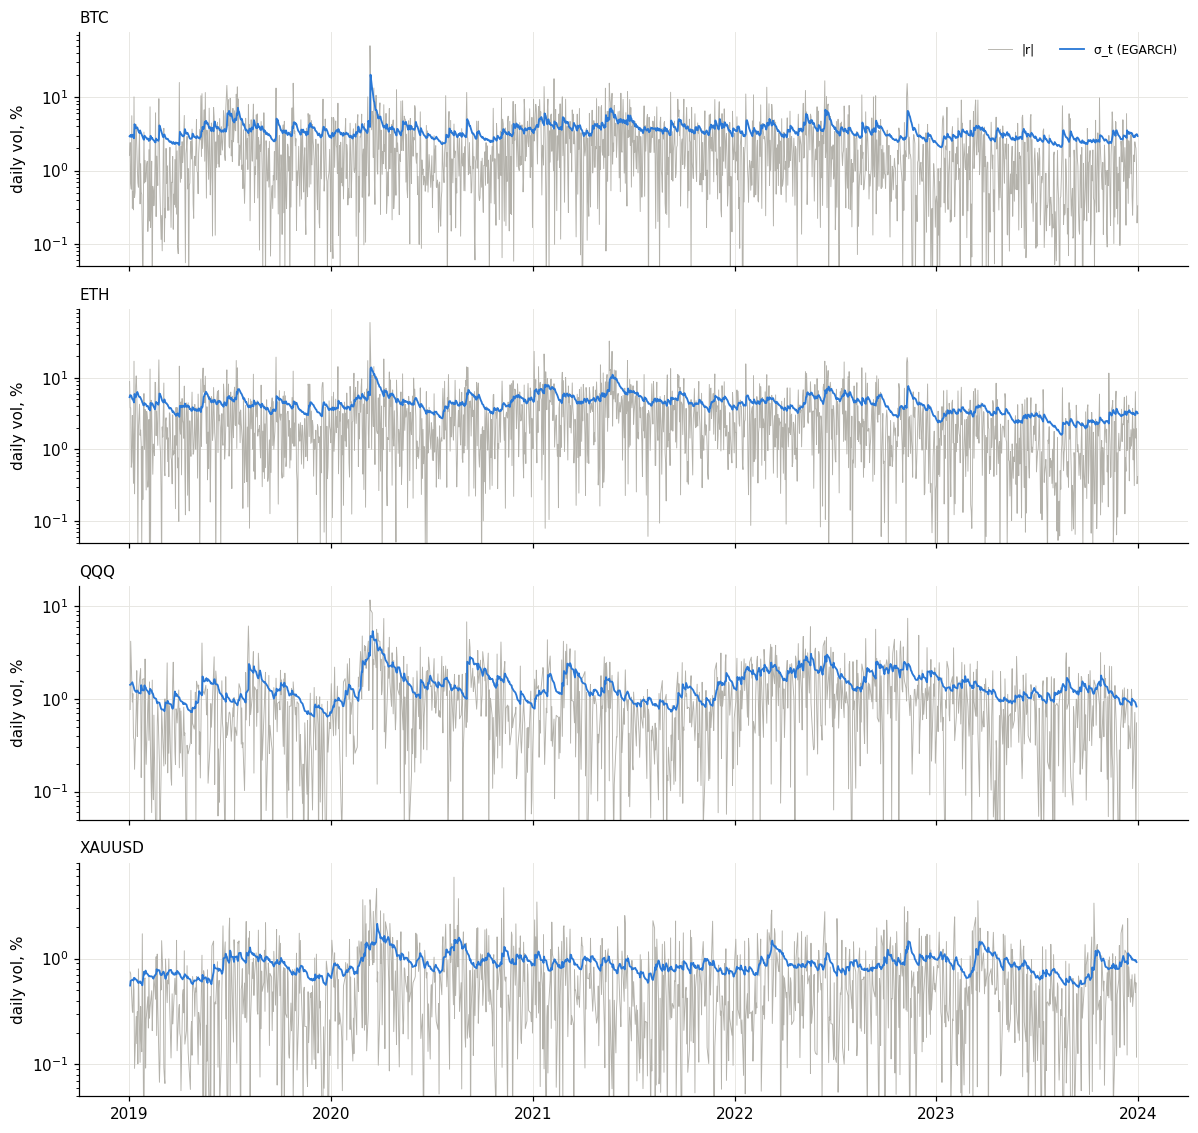

In [8]:
fig, axes = plt.subplots(len(ASSETS), 1, figsize=(11, 2.6 * len(ASSETS)), sharex=True)
for ax, s in zip(axes, ASSETS):
    res, rf = fits[s, 2024]
    ax.plot(rf.index, rf.abs().clip(lower=0.01), color=C['realized'], lw=0.6, label='|r|')
    ax.plot(rf.index, res.conditional_volatility, color=C['sigma'], lw=1.2, label='σ_t (EGARCH)')
    ax.set_yscale('log'); ax.set_ylim(bottom=0.05)
    ax.set_title(s, loc='left', fontsize=10); ax.set_ylabel('daily vol, %')
axes[0].legend(loc='upper right', ncol=2, frameon=False, fontsize=8)
fig.tight_layout()

# Walk-forward forecasts: EGARCH vs GARCH vs HAR-YZ vs naive

Fold Y uses the parameters fitted on returns dated ≤ 31 Dec of Y−1, held fixed through Y. With fixed parameters the model runs day by day:
ln σ²_{t+1} = ω + α(|z_t| − √(2/π)) + γ z_t + β ln σ²_t, using returns up to t only. The one-step forecast is exactly σ²_{t+1} (no log-to-variance bias at horizon 1).

HAR-YZ and GARCH forecasts come from `forecasts/<SYM>-HAR-YZ.csv` and `forecasts/<SYM>-GARCH11.csv`. Naive = `yz_var_22`. Target = `r2_next` (provisional; see README "Scoring target"). Units: %².

| Split | Target dates |
|---|---|
| Train | 2021-01-01 → 2023-12-31 |
| Test | 2024-01-01 → 2026-09-30 |

In [9]:
SPLITS = {'train': (pd.Timestamp('2021-01-01', tz='UTC'), pd.Timestamp('2024-01-01', tz='UTC')),
          'test':  (pd.Timestamp('2024-01-01', tz='UTC'), pd.Timestamp('2026-10-01', tz='UTC'))}
MODELS = ['naive', 'HAR-YZ', 'GARCH', 'EGARCH']

def egarch_one_step(r, p):
    """σ²_{t+1} made at the close of t, for every t, under fixed params."""
    am = arch_model(r, mean='Zero', vol='EGARCH', p=1, o=1, q=1, dist='normal', rescale=False)
    sig2 = am.fix(p).conditional_volatility ** 2
    z = r / np.sqrt(sig2)
    return np.exp(p['omega'] + p['alpha[1]'] * (z.abs() - np.sqrt(2 / np.pi))
                  + p['gamma[1]'] * z + p['beta[1]'] * np.log(sig2))

# cross-check against arch's own 1-step forecast
_p = fits['QQQ', 2024][0].params
_a = arch_model(rets['QQQ'], mean='Zero', vol='EGARCH', p=1, o=1, q=1, rescale=False).fix(_p) \
        .forecast(horizon=1, start=0, reindex=False).variance['h.1']
assert np.allclose(egarch_one_step(rets['QQQ'], _p), _a)

def read_fc(sym, model):
    f = pd.read_csv(FC / f'{sym}-{model}.csv', index_col=0)
    f.index = pd.to_datetime(f.index, utc=True)
    f['target_date'] = pd.to_datetime(f.target_date, utc=True)
    return f

comp = {}
for s in ASSETS:
    yz = yzd[s]
    har, gar = read_fc(s, 'HAR-YZ'), read_fc(s, 'GARCH11')
    rows = []
    for split, (a, b) in SPLITS.items():
        o = yz.index[(yz.target_date >= a) & (yz.target_date < b)]
        years = pd.DatetimeIndex(yz.target_date.loc[o]).year
        e = pd.Series(np.nan, index=o)
        for y in np.unique(years):
            e[years == y] = egarch_one_step(rets[s], fits[s, y][0].params).reindex(o[years == y]).to_numpy()
        rows.append(pd.DataFrame({'split': split, 'fold': years, 'target_date': yz.target_date.loc[o],
                                  'naive': yz.yz_var_22.loc[o] * 1e4, 'HAR-YZ': har.h.reindex(o),
                                  'GARCH': gar.h.reindex(o), 'EGARCH': e,
                                  'realized': yz.r2_next.loc[o] * 1e4}, index=o))
    comp[s] = pd.concat(rows)
    assert comp[s][MODELS + ['realized']].notna().all().all(), s
    for f in (har, gar):
        assert (f.target_date.reindex(comp[s].index) == comp[s].target_date).all(), s
    comp[s][['target_date', 'split', 'fold', 'EGARCH']].rename(columns={'EGARCH': 'h'}).to_csv(FC / f'{s}-EGARCH11.csv')
{s: c.split.value_counts().to_dict() for s, c in comp.items()}

{'BTC': {'train': 1095, 'test': 1004},
 'ETH': {'train': 1095, 'test': 1004},
 'QQQ': {'train': 753, 'test': 689},
 'XAUUSD': {'train': 773, 'test': 710}}

In [10]:
def score(f):
    ok = (f[MODELS] > 0).all(axis=1)
    g, rv = f[ok], f.realized[ok]
    out = pd.DataFrame({m: {'RMSE': np.sqrt(np.mean((g[m] - rv)**2)),
                            'QLIKE': np.mean(np.log(g[m]) + rv / g[m])} for m in MODELS}).T
    out['RMSE/naive'] = out.RMSE / out.loc['naive', 'RMSE']
    out['ΔQLIKE vs naive'] = out.QLIKE - out.loc['naive', 'QLIKE']
    out['dropped'], out['n'] = int((~ok).sum()), int(ok.sum())
    return out

scores = pd.concat({(s, sp): score(c[c.split == sp]) for s, c in comp.items() for sp in SPLITS})
scores.round(3)

RMSE  QLIKE  RMSE/naive  ΔQLIKE vs naive  dropped     n
BTC    train naive   28.457  3.428       1.000            0.000        0  1095
             HAR-YZ  26.588  3.401       0.934           -0.027        0  1095
             GARCH   27.052  3.396       0.951           -0.032        0  1095
             EGARCH  26.684  3.375       0.938           -0.053        0  1095
       test  naive   14.369  2.818       1.000            0.000        0  1004
             HAR-YZ  14.595  2.876       1.016            0.058        0  1004
             GARCH   14.356  2.796       0.999           -0.021        0  1004
             EGARCH  14.278  2.812       0.994           -0.006        0  1004
ETH    train naive   56.003  3.791       1.000            0.000        0  1095
             HAR-YZ  52.831  3.855       0.943            0.063        0  1095
             GARCH   52.991  3.821       0.946            0.029        0  1095
             EGARCH  52.615  3.810       0.939            0.018        0  1095
       test  naive   31.516  3.631       1.000            0.000        0  1004
             HAR-YZ  30.857  3.534       0.979           -0.098        0  1004
             GARCH   30.615  3.545       0.971           -0.086        0  1004
             EGARCH  30.434  3.553       0.966           -0.079        0  1004
QQQ    train naive    4.066  1.634       1.000            0.000        0   753
             HAR-YZ   4.232  1.678       1.041            0.044        0   753
             GARCH    4.220  1.679       1.038            0.045        0   753
             EGARCH   4.148  1.644       1.020            0.010        0   753
       test  naive    6.887  1.477       1.000            0.000        0   689
             HAR-YZ   6.457  1.377       0.937           -0.100        0   689
             GARCH    6.872  1.430       0.998           -0.047        0   689
             EGARCH   6.627  1.390       0.962           -0.086        0   689
XAUUSD train naive    1.395  0.734       1.000            0.000        0   773
             HAR-YZ   1.379  0.694       0.989           -0.041        0   773
             GARCH    1.400  0.728       1.004           -0.007        0   773
             EGARCH   1.395  0.735       1.001            0.000        0   773
       test  naive    4.766  1.459       1.000            0.000        0   710
             HAR-YZ   4.509  1.413       0.946           -0.047        0   710
             GARCH    4.521  1.417       0.949           -0.042        0   710
             EGARCH   4.569  1.416       0.959           -0.043        0   710

In [11]:
# ΔQLIKE per fold (lower = better). 'EGARCH − GARCH' < 0: asymmetry helped that year
rows = {}
for s, c in comp.items():
    for y, g in c.groupby('fold'):
        q = score(g).QLIKE
        rows[s, y] = {'EGARCH − naive': q['EGARCH'] - q['naive'], 'EGARCH − GARCH': q['EGARCH'] - q['GARCH'],
                      'EGARCH − HAR-YZ': q['EGARCH'] - q['HAR-YZ'], 'split': g.split.iloc[0]}
pd.DataFrame(rows).T.rename_axis(['asset', 'fold']).round(3)

EGARCH − naive EGARCH − GARCH EGARCH − HAR-YZ  split
asset  fold                                                     
BTC    2021      -0.037529      -0.033227        0.050517  train
       2022       -0.09908      -0.006296       -0.010959  train
       2023      -0.022774      -0.023582       -0.117743  train
       2024         0.0118       0.011132       -0.020742   test
       2025       0.042476       0.021629       -0.098951   test
       2026      -0.093898       0.013256       -0.075569   test
ETH    2021      -0.036512       0.011701        0.037855  train
       2022      -0.080315      -0.009939        0.007996  train
       2023       0.171944      -0.034688       -0.180299  train
       2024      -0.017966      -0.016587       -0.035213   test
       2025      -0.115222       0.005651        0.049645   test
       2026       -0.11093       0.043627        0.050384   test
QQQ    2021      -0.002995      -0.027899        0.020664  train
       2022       0.013793       -0.05197       -0.093255  train
       2023       0.019431      -0.025719       -0.029481  train
       2024      -0.061056      -0.017375       -0.002868   test
       2025      -0.146944       -0.06142         0.00622   test
       2026      -0.039442      -0.038753        0.044526   test
XAUUSD 2021       0.053821       0.025334        0.088075  train
       2022       0.034725      -0.007202        0.057566  train
       2023      -0.087719       0.003323       -0.022832  train
       2024      -0.077502      -0.019051       -0.025579   test
       2025      -0.085693      -0.023237       -0.021526   test
       2026       0.061005       0.052941        0.077512   test

## Test forecasts vs realized (daily volatility, %, log scale)

√(forecast variance) vs |next-day return|. Naive left out to keep the plot readable (it is in the tables).

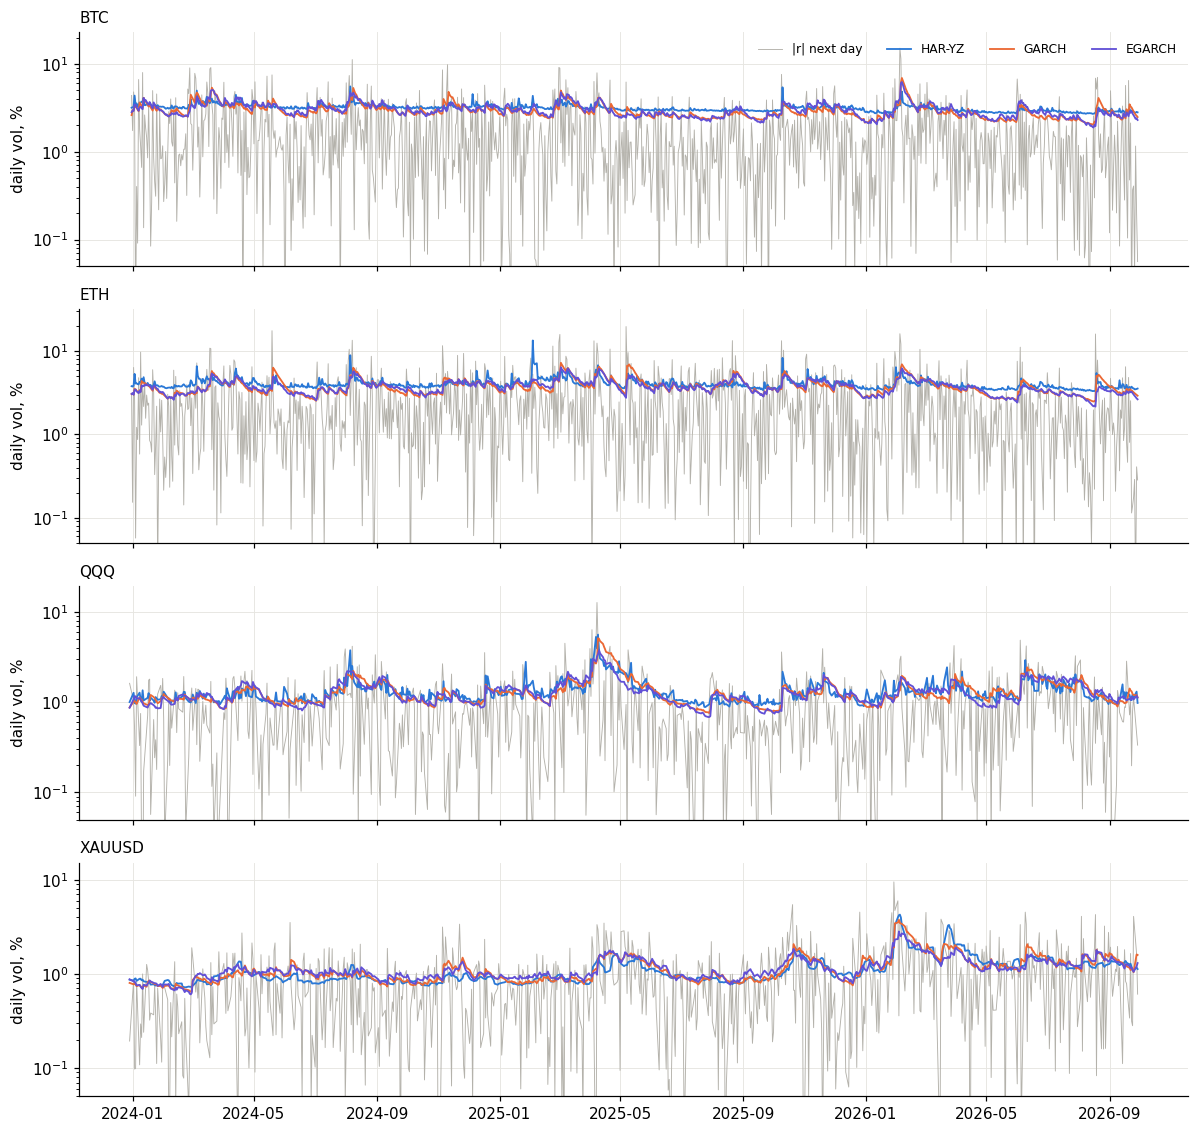

In [12]:
CC = {'realized': '#b4b2ab', 'HAR-YZ': '#2a78d6', 'GARCH': '#eb6834', 'EGARCH': '#6250d6'}
fig, axes = plt.subplots(len(ASSETS), 1, figsize=(11, 2.6 * len(ASSETS)), sharex=True)
for ax, s in zip(axes, ASSETS):
    f = comp[s][comp[s].split == 'test']
    ax.plot(f.index, np.sqrt(f.realized), color=CC['realized'], lw=0.6, label='|r| next day')
    for m in ['HAR-YZ', 'GARCH', 'EGARCH']:
        ax.plot(f.index, np.sqrt(f[m]), color=CC[m], lw=1.2, label=m)
    ax.set_yscale('log'); ax.set_ylim(bottom=0.05)
    ax.set_title(s, loc='left', fontsize=10); ax.set_ylabel('daily vol, %')
axes[0].legend(loc='upper right', ncol=4, frameon=False, fontsize=8)
fig.tight_layout()

## Findings (run 2026-11-01; target r², provisional)

**Fit:** all 24 fits converge cleanly (flag 0, no warnings, finite SEs, β ≤ 0.982). All 18 restarts per fit reach the same peak (gain 0.0, parameter ranges ≤ 1e-4).

**Asymmetry γ differs by asset, as the guide allows:**

| Asset | γ (folds 2021–2026) | Significant? | Meaning |
|---|---|---|---|
| QQQ | −0.10 to −0.11 | Yes from fold 2022 (p ≤ 0.02) | Leverage effect: down moves raise vol more |
| XAUUSD | **+0.05 to +0.09** | Yes in 5 of 6 folds (p < 0.05) | Reverse: **up** moves raise vol more |
| BTC | −0.06 to −0.11 | No (p 0.14–0.26) | Weak tilt, not established |
| ETH | −0.01 to −0.10 | No (p 0.28–0.81) | Symmetric |

**Forecasts, QLIKE vs naive (lower = better):**

| Asset | Train GARCH | Train EGARCH | Test HAR-YZ | Test GARCH | Test EGARCH |
|---|---:|---:|---:|---:|---:|
| BTC | −0.032 | **−0.053** | +0.058 | **−0.021** | −0.006 |
| ETH | +0.029 | **+0.018** | **−0.098** | −0.086 | −0.079 |
| QQQ | +0.045 | **+0.010** | **−0.100** | −0.047 | −0.086 |
| XAUUSD | −0.007 | 0.000 | −0.047 | −0.042 | −0.043 |

- **Asymmetry pays off only for QQQ,** the asset with a significant leverage effect. EGARCH beats GARCH in all 6 QQQ folds (test −0.086 vs −0.047). On test, HAR-YZ is still slightly ahead (−0.100). On train, EGARCH was best of all three.
- **Gold:** γ is significant, but EGARCH ≈ GARCH (test −0.043 vs −0.042; 3 folds better, 3 worse). A real asymmetry that doesn't improve next-day forecasts.
- **Crypto:** γ is not significant. EGARCH is better on train but worse on test for BTC and ETH, so there is no stable gain. GARCH is enough, per the guide's rule (prefer EGARCH only with evidence of improvement).
- Not tested for significance yet (Diebold–Mariano pending).
- Forecasts saved to `forecasts/<SYM>-EGARCH11.csv`.